# Part 12: Preparing Data Sets {-}

In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Data rarely arrive to us in a form such that they are ready for
formal analysis. Typically, steps of preprocessing, cleaning,
checking, etc. are required before we have what we can call
**ready data**.

You will note that I avoid using the term **clean data**, as this
can imply a complete lack of issues in the data set. Completely
"clean" data is not realistic, and should not be expected. The
best we can hope is that a data set is sufficiently processed
to minimize any biases that may result from errors in the data set.

Ultimately, this process is quite situation-specific. Here we present
some key concepts and stress the importance of taking these steps, but
each data set will present unique challenges. This topic will be
revisited throughout the course as we encounter new data sets.

Our discussion will initially focus on data sets that are naturally
represented in a **flat** or **spreadsheet** form.
Each column contains a different **variable** and each
row gives one **instance** or **case**.

**Exercise:** Give examples of cases and associated variables in
data sets typically encountered in finance.

\answerlines{5}

\newpage

When is a data set "ready?" We will break this down into the following five steps:

1. Each variable is understood.
2. The values the variable takes are interpretable, consistent, and stored in an appropriate form.
3. Each variable can satisfy logical constraints.
4. The distribution of each variable is inspected, with skewness and outliers noted.
5. The pattern of any missing values is explored, and the source of missingness is considered.

## Example Data Set {-}

First, we will read in a data set for use in some
subsequent examples.

Visit the website

__[https://bit.ly/31QyYjK](https://www.sec.gov/opa/data/market-structure/marketstructuredownloadshtml-by_security.html)__

and download the data from the second quarter of 2024. Create a directory
for working on these examples, and place this file in that directory.

These data come from the U.S. Securities and Exchange Commission
respository on market structure. This data set contains daily
characteristics of a range of market variables over 7500 equities and
ETFs, accumulated over several exchanges. See also

__[https://www.sec.gov/marketstructure/mar_methodology.html](https://www.sec.gov/marketstructure/mar_methodology.html)__

\newpage

Be sure that the working directory is correctly set in Python (use `chdir` from `os` if necessary)
and use `read_csv` from `pandas`:

In [2]:
ms2024q2 = pd.read_csv("q2_2024_all.csv")

**Exercise:** Inspect the data to ensure it was read in successfully. How large is the data set?

\answerlines{10}

Background on the data can be found in the associated `README` file, available on Canvas in the "Data Sets" folder in the "Files" page. We will reference portions of it below.

\newpage

## Step 1: Understanding the Variables {-}

Whenever a new data set is encountered, one should work to understand its variables (columns). Part of this process should include ensuring that the variables have properly descriptive names in the data frame.

The above-mentioned references provide more detail, but here are some important points for understanding this data set:

1. Data is gathered daily on activity from the following 12 exchanges: Amex (NYSE American), Arca, Bats-Y, Bats-Z, Boston, CHX (NYSE Chicago), Edga-A, Edge-X, Nasdaq, NSX (NYSE National), NYSE, and PHLX.

2. The data provides information on **orders** and **trades** on the exchanges for a large number of stocks and ETFs.

3. **Hidden orders** are orders structured in a way to conceal aspects of the order. An example is an
**iceberg order** in which a large volume order can be broken up into smaller pieces, where each piece is
only revealed publicly as the previous one is executed. The column denoted *Hidden* is the total number of trades executed against hidden orders, while *HiddenVol* gives the total volume of shares on these trades. Also reported
are *TradesForHidden* and *TradeVolForHidden*, which give the total number of trades and trading volume,
respectively, **on the exchanges which report trades against
hidden orders**, since not all of the exchanges do so. Exchanges prioritize **lit orders** over hidden orders.

4. An **odd lot** trade is one which involves fewer than 100 shares (with exceptions for BH, BRK.A, and SEB, which have relatively high share prices). The data set includes *OddLots* and *OddLotVol* to report the number of odd lot trades, and their total volume. The columns *TradesForOddLots* and *TradeVolForOddLots* are defined similarly to *TradesForHidden* and *TradeVolForHidden*. (This definition was updated in 2025. See the documentation.)

5. **Lit trades** is the difference between the total number of trades and the number of trades against hidden orders.

6. **Cancelled orders** are counted in the variable *Cancels*.

7. The columns *McapRank*, *TurnRank*, *VolatilityRank*, and *PriceRank* describe 
characteristics of the stock/ETF relative to others of its own type, namely the **market capitalization**, **turnover**, **volatility**, and
the **price**. Turnover is defined as the number of shares traded divided by the total number of shares
outstanding. Volatility is defined as the "daily SD of 1-minute quote midpoint returns." Price is the closing price.

**Exercise:** Why are the variables *TradesForHidden*, *TradeVolForHidden*, *TradesForOddLots*, and *TradeVolForOddLots* included?

\answerlines{5}

\newpage

## Step 2: Ensuring Values are Interpretable, Consistent, and Stored Appropriately {-}

In this step we explore the values that each variable takes and ensure that these are fully understood. Different columns present different challenges, so we will consider them separately.

One thing we will consider is which **scale** each variable is on, so that it can be appropriately interpreted and stored.

**Exercise:** Describe the distinctions between the variables which are on the categorical, ordinal, and ratio scales.

\answerlines{14}

**Date Column**

Initially, the first column in `ms2024q2` is a date stamp for the observation. Python/Pandas has special functions
for handling dates which will prove useful, especially when working with time series.

Initially the dates are simply integers.

In [3]:
print(ms2024q2['Date'][0])

20240401


The function `to_datetime` in Pandas will make the conversion. The list below shows all of the formatting characters. 

In [4]:
ms2024q2['Date'] = pd.to_datetime(ms2024q2['Date'], format='%Y%m%d')

**After**, having made this conversion, it is good practice to set the date as the row index.

In [5]:
ms2024q2 = ms2024q2.set_index('Date')

Now you can refer to data ranges using syntax such as the following:

In [6]:
ms2024q2.loc['2024-04']
ms2024q2.loc['2024-04-01':'2024-04-03']

,Security,Ticker,McapRank,TurnRank,VolatilityRank,PriceRank,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000)
Date,,,,,,,,,,,,,,,,,,
2024-04-01,Stock,A,10.0,3.0,1.0,10.0,339.128,64931.243,3438.0,15135.0,114.271,453.399,613365.0,11677.0,13151.0,15113.0,215.026,452.887
2024-04-01,Stock,AA,9.0,10.0,6.0,7.0,1498.025,95376.107,3881.0,26391.0,299.383,1797.408,503335.0,22465.0,16538.0,26346.0,435.589,1795.333
2024-04-01,Stock,AACI,3.0,1.0,8.0,5.0,2.175,85.178,9.0,26.0,0.630,2.805,366.0,17.0,14.0,26.0,0.266,2.805
2024-04-01,Stock,AADI,3.0,7.0,8.0,2.0,81.711,3077.388,422.0,1133.0,14.525,96.236,20310.0,710.0,754.0,1132.0,17.188,96.136
2024-04-01,Stock,AAGR,2.0,5.0,10.0,1.0,106.806,956.183,161.0,617.0,98.876,205.682,3338.0,456.0,108.0,617.0,4.212,205.682
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-03,ETF,ZTAX,1.0,1.0,4.0,2.0,0.003,159.903,0.0,2.0,0.000,0.003,1278.0,2.0,2.0,2.0,0.003,0.003
2024-04-03,ETF,ZTEN,1.0,3.0,1.0,3.0,1.871,4065.300,1.0,8.0,0.019,1.890,17871.0,7.0,4.0,8.0,0.037,1.890
2024-04-03,ETF,ZTRE,1.0,1.0,1.0,3.0,0.511,610.818,0.0,4.0,0.000,0.511,4059.0,4.0,1.0,4.0,0.009,0.511


\newpage

**Exercise:** What does the following syntax do?

\answerlines{7}

In [7]:
ms2024q2[ms2024q2['Ticker']=='AACI']['Hidden'].rolling('5D').mean()

Date
2024-04-01    9.000000
2024-04-02    5.000000
2024-04-03    6.000000
2024-04-04    7.250000
2024-04-05    9.400000
                ...   
2024-06-24    4.333333
2024-06-25    6.333333
2024-06-26    6.000000
2024-06-27    4.500000
2024-06-28    3.600000
Name: Hidden, Length: 63, dtype: float64

Format conversions can be achieved using `strftime`.

In [8]:
print(ms2024q2.index.strftime('%m/%y')[:2])
print(ms2024q2.index.strftime('%A, %B %d')[:2])

Index(['04/24', '04/24'], dtype='object', name='Date')
Index(['Monday, April 01', 'Monday, April 01'], dtype='object', name='Date')


\newpage

\large (From `https://stackabuse.com/how-to-format-dates-in-python/`.) \Large

\vspace{-.2in}
* `%b`: Returns the first three characters of the month name.
* `%d`: Returns day of the month, from 1 to 31.
* `%Y`: Returns the year in four-digit format.
* `%H`: Returns the hour.
* `%M`: Returns the minute, from 00 to 59.
* `%S`: Returns the second, from 00 to 59.
* `%a`: Returns the first three characters of the weekday, e.g. Wed.
* `%A`: Returns the full name of the weekday, e.g. Wednesday.
* `%B`: Returns the full name of the month, e.g. September.
* `%w`: Returns the weekday as a number, from 0 to 6, with Sunday as 0.
* `%m`: Returns the month as a number, from 01 to 12.
* `%p`: Returns AM/PM for time.
* `%y`: Returns the year in two-digit format, that is, without the century.
* `%f`: Returns microsecond from 000000 to 999999.
* `%Z`: Returns the timezone.
* `%z`: Returns UTC offset.
* `%j`: Returns the number of the day in the year, from 001 to 366.
* `%W`: Returns the week number of the year, from 00 to 53, with Monday being counted as the first day of the week.
* `%U`: Returns the week number of the year, from 00 to 53, with Sunday counted as the first day of each week.
* `%c`: Returns the local date and time version.
* `%x`: Returns the local version of date.
* `%X`: Returns the local version of time.

\newpage

**Columns 0 and 1: Security and Ticker**

(The column numbers refer to the current data frame, with Date converted to the row index.)

The variables `Security` and `Ticker` are currently of type `object`, which is how Pandas stores strings.

In [9]:
ms2024q2[['Security','Ticker']].dtypes

Security    object
Ticker      object
dtype: object

Both of these variables are clearly categorical, lacking in a natural ordering to the levels. The conversion to the appropriate data type is shown below. (By default, the categories are taken to be unordered.)

In [10]:
ms2024q2['Security'] = ms2024q2['Security'].astype('category')
ms2024q2['Ticker'] = ms2024q2['Ticker'].astype('category')

ms2024q2[['Security','Ticker']].dtypes

Security    category
Ticker      category
dtype: object

\newpage

We can see that there are two possible levels for `Security`, `Stock` or `ETF` (Exchange Traded Fund). There are over 7,500 symbols under consideration.

In [11]:
print(ms2024q2['Security'].unique())
print(len(ms2024q2['Ticker'].unique()))

['Stock', 'ETF']
Categories (2, object): ['ETF', 'Stock']
7539


**Exercise:** How many of the different ticker symbols are ETFs?

\answerlines{5}

\newpage

**Columns 2 through 5: Stock/ETF Characteristics**

The next four columns provide information on the stocks/ETFs
with respect to key attributes of Market Capitalization,
Turnover, Volatility, and Price.

In general, we would prefer to start with data in its
most "raw" format, and one could construct variables such
as these from that data. Alas, we are often left to work
with what is avaiable.

**Exercise:** What do the following operations do in Python?

In [12]:
ms2024q2.groupby(by=['Date','Security','McapRank'])

\answerlines{5}

In [13]:
grps = ms2024q2.groupby(by=['Date','Security','McapRank'])

\answerlines{6}

In [14]:
for name, group in grps:
    print(name)
    print(group)
    print()

(Timestamp('2024-04-01 00:00:00'), 'ETF', np.float64(1.0))
           Security Ticker  McapRank  TurnRank  VolatilityRank  PriceRank  \
Date                                                                        
2024-04-01      ETF    AAA       1.0       4.0             1.0        2.0   
2024-04-01      ETF   AAPB       1.0       4.0             4.0        1.0   
2024-04-01      ETF   AAPX       1.0       4.0             4.0        1.0   
2024-04-01      ETF   AAPY       1.0       4.0             4.0        1.0   
2024-04-01      ETF   ABCS       1.0       3.0             3.0        2.0   
...             ...    ...       ...       ...             ...        ...   
2024-04-01      ETF   ZTAX       1.0       1.0             4.0        2.0   
2024-04-01      ETF   ZTEN       1.0       2.0             1.0        3.0   
2024-04-01      ETF   ZTRE       1.0       2.0             1.0        3.0   
2024-04-01      ETF   ZTWO       1.0       4.0             1.0        3.0   
2024-04-01      E

           Security Ticker  McapRank  TurnRank  VolatilityRank  PriceRank  \
Date                                                                        
2024-04-03      ETF   AAAU       4.0       4.0             4.0        1.0   
2024-04-03      ETF   AAXJ       4.0       4.0             2.0        4.0   
2024-04-03      ETF   ACIO       4.0       2.0             2.0        3.0   
2024-04-03      ETF   ACWI       4.0       4.0             2.0        4.0   
2024-04-03      ETF   ACWV       4.0       1.0             1.0        4.0   
...             ...    ...       ...       ...             ...        ...   
2024-04-03      ETF     XT       4.0       2.0             3.0        4.0   
2024-04-03      ETF   XYLD       4.0       3.0             1.0        3.0   
2024-04-03      ETF   YEAR       4.0       3.0             1.0        4.0   
2024-04-03      ETF   YINN       4.0       4.0             4.0        1.0   
2024-04-03      ETF   ZROZ       4.0       4.0             4.0        4.0   

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



\answerlines{3}

In [15]:
print(grps.count()["Ticker"].to_string())

Date        Security  McapRank
2024-04-01  ETF       1.0         840
                      2.0         840
                      3.0         840
                      4.0         840
                      5.0           0
                      6.0           0
                      7.0           0
                      8.0           0
                      9.0           0
                      10.0          0
            Stock     1.0         398
                      2.0         398
                      3.0         398
                      4.0         397
                      5.0         398
                      6.0         397
                      7.0         398
                      8.0         398
                      9.0         397
                      10.0        398
2024-04-02  ETF       1.0         841
                      2.0         841
                      3.0         841
                      4.0         841
                      5.0           0
                   

\answerlines{3}

**Exercise:** What does this tell us about the structure of these variables? Why should we be very careful with these variables?

\answerlines{8}

\newpage

We change these into **ordered categorical variables** to reflect their ordinal nature.

We say that a variable has **internal consistency** if, for that variable, observations with the same value signify the same thing. It is uncommon for a variable for not have internal consistency, but we have just seen an example of a case where it fails.

In [16]:
ms2024q2['McapRank'] = ms2024q2['McapRank'].astype('category').cat.as_ordered()
ms2024q2['TurnRank'] = ms2024q2['TurnRank'].astype('category').cat.as_ordered()
ms2024q2['VolatilityRank'] = ms2024q2['VolatilityRank'].astype('category').cat.as_ordered()
ms2024q2['PriceRank'] = ms2024q2['PriceRank'].astype('category').cat.as_ordered()

\newpage

**Exercise:** Consider the output of the following command. Does Python appropriate handle the categorical variable `McapRank`?

\answerlines{5}

In [17]:
ms2024q2stocks = ms2024q2[ms2024q2['Security']=="Stock"]

import statsmodels.api as sm

sm.OLS.from_formula(formula="Hidden~McapRank",data=ms2024q2stocks).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Hidden   R-squared:                       0.186
Model:                            OLS   Adj. R-squared:                  0.186
Method:                 Least Squares   F-statistic:                     6308.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:47   Log-Likelihood:            -2.4452e+06
No. Observations:              249225   AIC:                         4.890e+06
Df Residuals:                  249215   BIC:                         4.891e+06
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          347.8020     27.934     12.451      0.000     293.052     402.552
McapRank[T.2.0]   -169.3535     39.517     -4.286      0.000    -246.805     -91.902
McapRank[T.3.0]    -74.4645     39.521     -1.884      0.060    -151.924       2.995
McapRank[T.4.0]    152.7462     39.543      3.863      0.000      75.244     230.248
McapRank[T.5.0]    468.6415     39.514     11.860      0.000     391.195     546.088
McapRank[T.6.0]    816.8263     39.521     20.668      0.000     739.365     894.287
McapRank[T.7.0]   1326.9883     39.519     33.578      0.000    1249.531    1404.445
McapRank[T.8.0]   1690.8251     39.519     42.785      0.000    1613.370    1768.281
McapRank[T.9.0]   2955.8395     39.544     74.749      0.000    2878.335    3033.344
McapRank[T.10.0]  7098.3906     39.507    179.673      0.000    7020.958    7175.824
==============================================================================
Omnibus:                   674801.869   Durbin-Watson:                   1.994
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      41855452429.796
Skew:                          33.268   Prob(JB):                         0.00
Kurtosis:                    2009.537   Cond. No.                         10.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

\newpage

**Columns 6 through 17: Counts**
    
The remaining columns in the data set are all counts, of numbers of orders, trades, and shares (trading volume) of different types.

All of these variables will be on the ratio scale.

Note that some of the variable names include the notation *('000)* to indicate that the counts are given in units of thousands.

\newpage

## Step 3: Checking Logical Constraints on Variables {-}

A good next step is to run a series of tests/checks on the data set, to ensure that the variables conform to restrictions that one may expect, i.e., that one would find "logical" or reasonable. Of course, there is no limit on how many such tests one could run, so a decision has to be made on the extent of such testing. Experience is often an important guide here: If in the past certain types of errors appear in data sets of similar form, tests for those errors should be constructed and run.

\newpage

**Checking for Duplicates**

It is a good idea to identify cases where there should not be repetitions in the rows of the data set, and identify any instances where this is violated. The `duplicated` syntax in Pandas is useful for this purpose.

**Exercise:** Run the command below and comment on what is found.

In [18]:
ms2024q2[ms2024q2.reset_index().duplicated(subset=['Date', 'Ticker'], keep=False).to_numpy()]

,Security,Ticker,McapRank,TurnRank,VolatilityRank,PriceRank,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000)
Date,,,,,,,,,,,,,,,,,,
2024-04-01,Stock,CWBC,NaN,NaN,10.0,NaN,96.820,1947.918,704.0,2012.0,74.060,170.880,13956.0,1286.0,1214.0,1980.0,30.214,168.988
2024-04-01,Stock,CWBC,5.0,10.0,10.0,6.0,96.820,1947.918,704.0,2012.0,74.060,170.880,13956.0,1286.0,1214.0,1980.0,30.214,168.988
2024-04-26,ETF,FPAG,NaN,NaN,3.0,NaN,0.162,11855.348,4.0,6.0,0.566,0.728,30382.0,2.0,4.0,6.0,0.328,0.728
2024-04-26,ETF,FPAG,2.0,2.0,3.0,2.0,0.162,11855.348,4.0,6.0,0.566,0.728,30382.0,2.0,4.0,6.0,0.328,0.728
2024-06-24,ETF,TIME,NaN,NaN,4.0,NaN,3.962,155608.582,0.0,22.0,0.000,3.962,119254.0,22.0,8.0,22.0,0.132,3.962
2024-06-24,ETF,TIME,1.0,4.0,4.0,2.0,3.962,155608.582,0.0,22.0,0.000,3.962,119254.0,22.0,8.0,22.0,0.132,3.962


\answerlines{7}

We can remove the duplicated rows found here by using the following syntax. Note that I am using `keep='last'` because in each instance I want to retain the second of the repeated pair.

In [19]:
ms2024q2 = ms2024q2.reset_index().drop_duplicates(subset=('Date','Ticker'), keep='last').set_index('Date')

\newpage

**Checking ranges**

The following syntax, using the `agg` method in Pandas, is useful for checking the range of each column.

**Exercise:** Run the command below, and comment.

In [20]:
ms2024q2.iloc[:,6:]

,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000)
Date,,,,,,,,,,,,
2024-04-01,339.128,64931.243,3438.0,15135.0,114.271,453.399,613365.0,11677.0,13151.0,15113.0,215.026,452.887
2024-04-01,1498.025,95376.107,3881.0,26391.0,299.383,1797.408,503335.0,22465.0,16538.0,26346.0,435.589,1795.333
2024-04-01,2.175,85.178,9.0,26.0,0.630,2.805,366.0,17.0,14.0,26.0,0.266,2.805
2024-04-01,81.711,3077.388,422.0,1133.0,14.525,96.236,20310.0,710.0,754.0,1132.0,17.188,96.136
2024-04-01,106.806,956.183,161.0,617.0,98.876,205.682,3338.0,456.0,108.0,617.0,4.212,205.682
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-06-28,3.452,775.338,28.0,111.0,0.998,4.450,6879.0,83.0,81.0,111.0,0.693,4.450
2024-06-28,0.100,3113.512,0.0,1.0,0.000,0.100,15519.0,1.0,0.0,1.0,0.000,0.100
2024-06-28,0.100,991.340,0.0,1.0,0.000,0.100,5019.0,1.0,0.0,1.0,0.000,0.100


In [21]:
ms2024q2.iloc[:,6:].agg(['min','max'])

,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000)
min,0.000,0.000000e+00,-1815.0,0.0,-243.127,0.000,2.0,0.0,0.0,0.0,0.000,0.000
max,720777.155,7.732356e+07,473231.0,1783018.0,122888.119,843665.274,50102254.0,1306883.0,1135211.0,1779920.0,25870.097,839037.034


\answerlines{3}

The next command will list those rows with negative values.

In [22]:
ms2024q2[(ms2024q2['Hidden']<0) | (ms2024q2["HiddenVol('000)"]<0)]

,Security,Ticker,McapRank,TurnRank,VolatilityRank,PriceRank,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000)
Date,,,,,,,,,,,,,,,,,,
2024-04-26,Stock,ZONE,2.0,10.0,10.0,3.0,661.853,6133.541,281.0,2618.0,-243.127,753.235,9405.0,1387.0,986.0,2068.0,37.984,607.748
2024-05-22,Stock,OGEN,1.0,10.0,10.0,2.0,286.358,4830.513,330.0,1742.0,-59.340,356.696,19986.0,985.0,638.0,1514.0,21.036,280.946
2024-05-31,Stock,ADRT,3.0,10.0,10.0,8.0,108.825,3036.579,-1815.0,7397.0,-30.719,135.654,28433.0,5051.0,6302.0,6597.0,70.209,117.399
2024-05-31,Stock,BITE,3.0,6.0,10.0,5.0,19.777,798.796,-60.0,547.0,3.305,31.193,6864.0,325.0,351.0,453.0,7.712,27.274
2024-06-21,Stock,TOON,2.0,4.0,10.0,1.0,29.204,1563.697,-114.0,156.0,-33.809,32.278,2604.0,105.0,70.0,121.0,2.121,25.260


**Exercise:** Do you have any theories as to why there are negative values for hidden trades and volume?

\answerlines{8}

\newpage

This endeavor is inherently situation-specific, and it is a good idea to take some time to think about what other constraints could be tested for a particular data set.

**Exercise:** What other constraints could you test with these data?

\answerlines{10}

\newpage

## Step 4: Inspecting the Distributions of Variables {-}

Each of the variables which is on the ratio scale should have their distribution inspected. Heavily skewed variables often create problems for analyses, e.g. the extreme observations are often influential points when used as predictors in a regression model. Transformations, including the power transformations discussed in the previous part, should be considered in such cases. 

Log transforming variables is particularly prevalent in finance since we often work with variables which are strictly positive, and whose distributions have long upper tails.

**Exercise:** Execute the command below and comment on the results.

In [23]:
ms2024q2.iloc[:,6:].describe(percentiles=[0.05,0.25,0.5,0.90,0.95,0.99])

,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000)
count,464161.000000,4.641610e+05,464161.000000,4.641610e+05,464161.000000,464161.000000,4.641610e+05,4.641610e+05,4.641610e+05,4.641610e+05,464161.000000,464161.000000
mean,390.078217,6.712035e+04,1042.370231,4.757466e+03,97.100754,487.181817,1.429889e+05,3.695103e+03,3.007110e+03,4.734613e+03,68.267565,484.673694
std,2893.255971,6.485964e+05,3725.384185,1.718558e+04,665.986937,3509.508255,6.757264e+05,1.394581e+04,1.068260e+04,1.713745e+04,259.988253,3497.897211
min,0.000000,0.000000e+00,-1815.000000,0.000000e+00,-243.127000,0.000000,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
5%,0.000000,1.270130e+02,0.000000,1.000000e+00,0.000000,0.001000,7.300000e+02,0.000000e+00,0.000000e+00,1.000000e+00,0.000000,0.001000
25%,1.220000,1.742422e+03,6.000000,2.800000e+01,0.367000,2.130000,5.657000e+03,1.600000e+01,1.300000e+01,2.800000e+01,0.285000,2.100000
50%,19.806000,7.456064e+03,94.000000,3.500000e+02,6.504000,27.680000,2.905200e+04,2.350000e+02,1.800000e+02,3.440000e+02,4.090000,27.372000
90%,634.596000,8.439768e+04,2785.000000,1.199300e+04,183.491000,827.602000,2.739510e+05,9.057000e+03,8.060000e+03,1.193600e+04,173.144000,823.651000
95%,1418.939000,1.721634e+05,4756.000000,2.109600e+04,368.867000,1794.330000,4.973710e+05,1.629600e+04,1.377700e+04,2.099700e+04,306.842000,1784.362000
99%,6562.883600,9.244144e+05,11474.400000,5.580800e+04,1416.677200,7950.982600,1.800894e+06,4.536680e+04,3.271740e+04,5.555000e+04,805.665200,7906.382200


\answerlines{10}

\newpage

Of course, graphical tools are useful for understanding the
distributions of variables. A simple, but useful, tool for this is the **boxplot**:

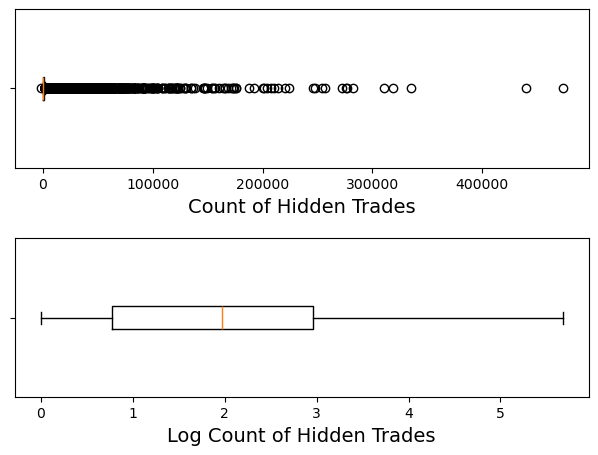

In [24]:
fig,axs=plt.subplots(2,1,figsize=[7,5])
fig.tight_layout(pad=3.0)
axs[0].boxplot(ms2024q2['Hidden'],labels=[""],vert=False)
axs[0].set_xlabel("Count of Hidden Trades",size=14)
axs[1].boxplot(np.log10(ms2024q2['Hidden']).dropna(),labels=[""], vert=False)
axs[1].set_xlabel("Log Count of Hidden Trades",size=14)
plt.show()

The "box" of the plot extends from the 25th to the 75th percentile
of the data, while the solid line in the middle of the box is at the
median. The two "arms" extend to the minimum and maximum value,
**except** that any value labelled an **outlier** is
plotted separately.

**Exercise:** How is an outlier defined in this case?

\answerlines{5}

**Exercise:** Why was the logarithm of the variable utilized?

\answerlines{10}

\newpage

**Isolation Forests**

**Isolation forests** are a more modern, useful technique for identifying outliers/anomalies in a data set.

The technique works by building a family of partitions of the data space. Each partitioning can be represented by a **tree**, and is constructed as follows: Choose one of the variables at random, and then choose (at random) a value within the range of that variable as the split point for that node of the tree. Repeatedly make these choices to grow out the tree until every observation is in a partition by itself, or a maximum depth is reached.

The result of this process is that observations which are anomalous will tend to end up at a higher level in the resulting tree, i.e., one would only need to go down few levels of the tree to reach that observation.

The above recipe is repeated many times. The score attached to an observation,
as defined in Liu, Ting, and Zhou (2008),
is such that
\begin{equation}
-\log_2(\mbox{score}) = \frac{\mbox{average depth for this observation}}{\mbox{average depth for all observations}}
\end{equation}
The Python implementation then takes the negative of this score, resulting in a value
between $-1$ and $0$, with outliers having scores closer to $-1$.


Some comments:
    
1. The recommended number of trees to create is 100, and this is the default chosen for `n_estimators`.
2. The maximum depth of a tree is set at $\log_2(n)$.
3. The entire training sample is not used for each tree. Instead a sample of data, of size `max_samples` is chosen at random. The default value is 256.

\newpage

Below is an example in two dimensions. Here, data are sampled from a $t$-distribution with five degrees of freedom.

In [25]:
from scipy.stats import t
simple_train = pd.DataFrame(t.rvs(5,size=[1000,2],random_state=0))

The following will fit the isolation forest and then calculate the score for each observation.

In [26]:
from sklearn.ensemble import IsolationForest

clf = IsolationForest(random_state=0)
clf.fit(simple_train)

simple_train["IFscore"] = clf.score_samples(simple_train)

\newpage

The figure below shows that observations at the extreme are assigned smaller scores.

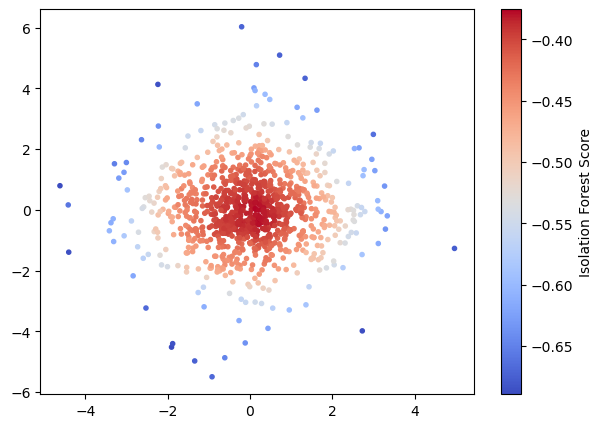

In [27]:
fig,axs=plt.subplots(1,1,figsize=[7,5])

scat = axs.scatter(simple_train.iloc[:,0],
    simple_train.iloc[:,1],c=(simple_train["IFscore"]),
    cmap="coolwarm",marker=".")
fig.colorbar(scat,label="Isolation Forest Score")
plt.show()

\newpage

Let's return to our data. It only makes sense to apply this method to the columns which are on the ratio scale.

In [28]:
clf = IsolationForest(random_state=0)
clf.fit(ms2024q2.iloc[:,6:])

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary ` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",0
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary `... versionadded:: 0.21",False


The following will convert these variables into their percentiles. This will make it easier to judge how extreme observations are relative to the others.

In [29]:
ms2024q2ranks = ms2024q2.copy()
ms2024q2ranks.iloc[:,6:] = ms2024q2ranks.iloc[:,6:].rank(pct=True)

ms2024q2ranks["IFscore"] = clf.score_samples(ms2024q2.iloc[:,6:])

**Exercise:** Comment on the output of the below command.

In [30]:
ms2024q2ranks.sort_values("IFscore")[:20]

,Security,Ticker,McapRank,TurnRank,VolatilityRank,PriceRank,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000),IFscore
Date,,,,,,,,,,,,,,,,,,,
2024-06-25,Stock,NVDA,10.0,9.0,7.0,9.0,0.999901,0.993905,0.999959,0.999983,0.999877,0.999903,0.999250,0.999985,0.999974,0.999983,0.999974,0.999903,-0.874030
2024-06-26,Stock,NVDA,10.0,9.0,7.0,9.0,0.999871,0.993058,0.999957,0.999976,0.999860,0.999864,0.999222,0.999983,0.999981,0.999976,0.999976,0.999866,-0.874030
2024-04-15,ETF,SPY,4.0,4.0,3.0,4.0,0.999653,0.998485,0.998473,0.999920,0.999158,0.999619,0.999976,0.999946,0.999720,0.999920,0.999832,0.999619,-0.874030
2024-04-29,Stock,TSLA,10.0,10.0,8.0,10.0,0.999713,0.993233,0.999974,0.999987,0.999825,0.999769,0.999485,0.999987,0.999991,0.999987,0.999989,0.999769,-0.874030
2024-06-21,Stock,NVDA,10.0,8.0,8.0,9.0,0.999916,0.993552,0.999991,0.999994,0.999935,0.999925,0.999362,0.999994,0.999996,0.999994,0.999991,0.999925,-0.874030
2024-06-24,Stock,NVDA,10.0,9.0,8.0,9.0,0.999935,0.994196,0.999987,0.999998,0.999912,0.999933,0.999373,0.999998,0.999998,0.999998,0.999998,0.999933,-0.874030
2024-04-05,Stock,TSLA,10.0,10.0,9.0,10.0,0.999470,0.989764,0.999938,0.999948,0.999720,0.999578,0.998985,0.999950,0.999961,0.999948,0.999953,0.999580,-0.873439
2024-04-24,Stock,TSLA,10.0,10.0,8.0,10.0,0.999567,0.991169,0.999944,0.999959,0.999711,0.999623,0.999274,0.999961,0.999970,0.999959,0.999978,0.999623,-0.873439
2024-06-20,Stock,NVDA,10.0,9.0,8.0,10.0,0.999950,0.992649,1.000000,1.000000,0.999963,0.999948,0.999291,1.000000,1.000000,1.000000,1.000000,0.999948,-0.873439


\answerlines{7}

\newpage

## Step 5: Checking for Missing Data {-}

Most data sets contain some amount of missing data, for
many reasons.

As a first step, it is important to recognize how your data set
represents missing values, so that they are read in properly.

In a `.csv` file such as that we are using here, it is common to
simply have blank values to indiciate missingness, i.e., there are
consecutive commas without a value between.

The `read_csv()` function has an argument `na_values` which allows
the user to specify strings that should be considered as missing
values. By default, the following are converted into `NaN`:
`‘’, ‘#N/A’, ‘#N/A N/A’, ‘#NA’, ‘-1.#IND’, ‘-1.#QNAN’, ‘-NaN’, ‘-nan’, ‘1.#IND’, ‘1.#QNAN’, ‘N/A’, ‘NA’, ‘NULL’, ‘NaN’, ‘n/a’, ‘nan’, ‘null’`.

**Be careful:** It is not unusual for
data sets to use numbers such as `-999` to indicate a missing value.

Pandas uses `NaN` to represent missing values.


\newpage

**Exercise:** Execute the following commands and discuss the results

In [31]:
np.where(ms2024q2.isnull())

(array([   198,    198,    198,    941,    941,    941,   2224,   2224,
          2224,  16673,  16673,  16673,  31831,  31831,  31831,  39848,
         39848,  39848, 104765, 104765, 104765, 179545, 179545, 179545,
        224396, 224396, 224396, 243458, 245848, 245848, 245848, 245969,
        245969, 245969, 257451, 257451, 257451, 280911, 280911, 280911,
        310706, 310706, 310706, 319639, 319639, 319639, 369000, 369000,
        369000, 407494, 414887, 419801, 419801, 419801, 422278, 429671,
        451874, 457562, 457562, 457562, 460415, 460415, 460415]),
 array([2, 3, 5, 2, 3, 5, 2, 3, 5, 2, 3, 5, 2, 3, 5, 2, 3, 5, 2, 3, 5, 2,
        3, 5, 2, 3, 5, 3, 2, 3, 5, 2, 3, 5, 2, 3, 5, 2, 3, 5, 2, 3, 5, 2,
        3, 5, 2, 3, 5, 4, 4, 2, 3, 5, 4, 4, 4, 2, 3, 5, 2, 3, 5]))

In [32]:
len(np.unique(np.where(ms2024q2.isnull())[0]))

25

\answerlines{15}

\newpage

The package `seaborn` has a function `heatmap()` that can be useful for inspecting any patterns in the missingness.

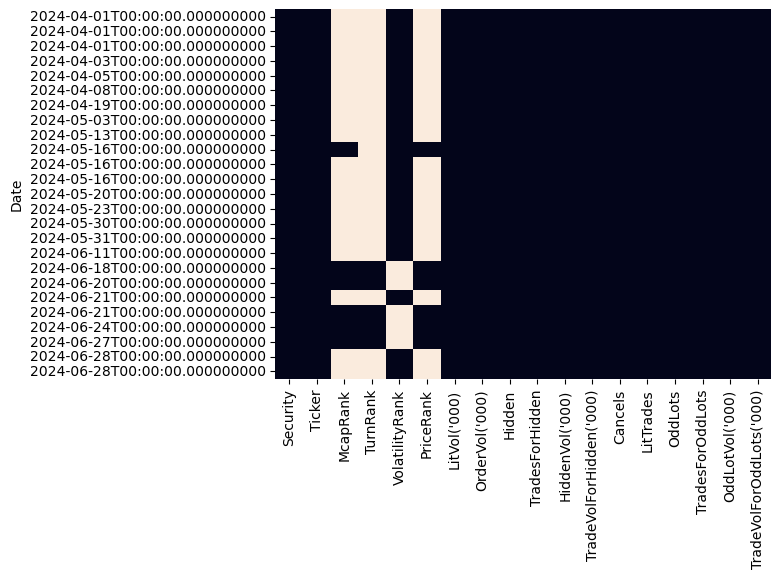

In [33]:
import seaborn as sns
sns.heatmap(ms2024q2.iloc[np.unique(np.where(ms2024q2.isnull())[0]),:].isnull(),cbar=False)
plt.show()

\newpage

The `dropna` function will remove any row from the data frame with at least one `NaN` value.

In [34]:
ms2024q2complete = ms2024q2.dropna()

Working only with such data is referred to as **complete case analysis**.

**Exercise:** Discuss potential drawbacks to complete case analyses.

\answerlines{10}

\newpage

**Exercise:** Consider the output of the following and comment on any features of the incomplete cases that may be releveant.

In [35]:
ms2024q2.iloc[np.unique(np.where(ms2024q2.isnull())[0]),:]

,Security,Ticker,McapRank,TurnRank,VolatilityRank,PriceRank,LitVol('000),OrderVol('000),Hidden,TradesForHidden,HiddenVol('000),TradeVolForHidden('000),Cancels,LitTrades,OddLots,TradesForOddLots,OddLotVol('000),TradeVolForOddLots('000)
Date,,,,,,,,,,,,,,,,,,
2024-04-01,Stock,AMNB,NaN,NaN,10.0,NaN,0.000,0.235,0.0,0.0,0.000,0.000,2.0,0.0,0.0,0.0,0.000,0.000
2024-04-01,Stock,CSTR,NaN,NaN,10.0,NaN,0.000,0.158,0.0,0.0,0.000,0.000,4.0,0.0,0.0,0.0,0.000,0.000
2024-04-01,Stock,MCAF,NaN,NaN,10.0,NaN,0.000,6.348,0.0,0.0,0.000,0.000,188.0,0.0,0.0,0.0,0.000,0.000
2024-04-03,Stock,KNTE,NaN,NaN,10.0,NaN,0.000,71.096,0.0,0.0,0.000,0.000,18.0,0.0,0.0,0.0,0.000,0.000
2024-04-05,Stock,NGM,NaN,NaN,10.0,NaN,0.000,23.517,0.0,0.0,0.000,0.000,4.0,0.0,0.0,0.0,0.000,0.000
2024-04-08,Stock,SCTL,NaN,NaN,10.0,NaN,0.000,358.182,0.0,0.0,0.000,0.000,10.0,0.0,0.0,0.0,0.000,0.000
2024-04-19,Stock,KAMN,NaN,NaN,1.0,NaN,0.000,0.000,0.0,0.0,0.000,0.000,4.0,0.0,0.0,0.0,0.000,0.000
2024-05-03,Stock,SMMF,NaN,NaN,1.0,NaN,0.000,0.027,0.0,0.0,0.000,0.000,2.0,0.0,0.0,0.0,0.000,0.000
2024-05-13,Stock,ZFOX,NaN,NaN,10.0,NaN,0.000,1.760,0.0,0.0,0.000,0.000,20.0,0.0,0.0,0.0,0.000,0.000


\answerlines{10}